In [13]:
import pandas as pd
import numpy as np
import keras
from keras import models
from keras import layers
from keras.models import Sequential
from keras.layers import Dense
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPRegressor
from sklearn.model_selection import train_test_split
from sklearn.model_selection import KFold
from sklearn.metrics import r2_score
from sklearn.metrics import mean_squared_error
import matplotlib.pyplot as plt

In [14]:
df = pd.read_csv("https://raw.githubusercontent.com/selva86/datasets/master/BostonHousing.csv")
df.head()

,crim,zn,indus,chas,nox,rm,age,dis,rad,tax,ptratio,b,lstat,medv
0,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,1,296,15.3,396.90,4.98,24.0
1,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242,17.8,396.90,9.14,21.6
2,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242,17.8,392.83,4.03,34.7
3,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222,18.7,394.63,2.94,33.4
4,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,3,222,18.7,396.90,5.33,36.2


In [15]:
X = df[['crim',
        'zn',
        'indus',
        'chas',
        'nox',
        'rm',
        'age',
        'dis',
        'rad',
        'tax',
        'ptratio',
        'b',
        'lstat']].values
Y = df['medv'].values

In [16]:
scaler = StandardScaler()
X = scaler.fit_transform(X)

In [17]:
# X_train, X_test, Y_train, Y_test = train_test_split(
#     X,
#     Y,
#     test_size=0.2,
#     random_state=42
# )

In [18]:
kf=KFold(n_splits=5,shuffle=True,random_state=42)

In [24]:
from keras.optimizers import Adam
from keras import regularizers

model=models.Sequential([
    keras.layers.Input(shape=(X.shape[1],) ),
    keras.layers.Dense( 64, activation="relu",kernel_regularizer=regularizers.l2(0.001)),
    keras.layers.Dense( 32, activation="relu",kernel_regularizer=regularizers.l2(0.001)),
    # keras.layers.Dense( 16, activation="relu",kernel_regularizer=regularizers.l2(0.001)),
    keras.layers.Dense(1)] )

# for train_index, test_index in kf.split(X):
#   X_train, X_test =X[train_index],X[test_index]
#   Y_train, Y_test =Y[train_index],Y[test_index]

# model.compile(optimizer=Adam(learning_rate=0.001),loss="mse")
# history=model.fit(X_train, Y_train,epochs=100,batch_size=16)

# Y_pred = model.predict(X_test)
# mse=mean_squared_error(Y_test, Y_pred)
# print("MSE:", mse)
# r2 = r2_score(Y_test, Y_pred)
# print("R² Score_1:", r2)

for split, (train_index, test_index) in enumerate(kf.split(X),1):
  X_train = X[train_index]
  X_test = X[test_index]
  Y_train = Y[train_index]
  Y_test = Y[test_index]

  model.compile(optimizer=Adam(learning_rate=0.001),loss="mse")
  history=model.fit(X_train, Y_train,epochs=100,batch_size=16,verbose=0)

  Y_pred = model.predict(X_test)
  mse=mean_squared_error(Y_test, Y_pred)
  print("MSE:", mse)
  r2 = r2_score(Y_test, Y_pred)
  print("R² Score for Split:", split,":",r2)

print("Final R² Score:", r2)

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
MSE: 10.836623911707843
R² Score for Split: 1 : 0.852228762178862
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step
MSE: 6.934462225696393
R² Score for Split: 2 : 0.9116920898517245
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step
MSE: 5.982213552648339
R² Score for Split: 3 : 0.9342458869085697
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step
MSE: 4.32550452833262
R² Score for Split: 4 : 0.9585866965966773
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step
MSE: 3.8499381454898494
R² Score for Split: 5 : 0.9464590375242687
Final R² Score: 0.9464590375242687


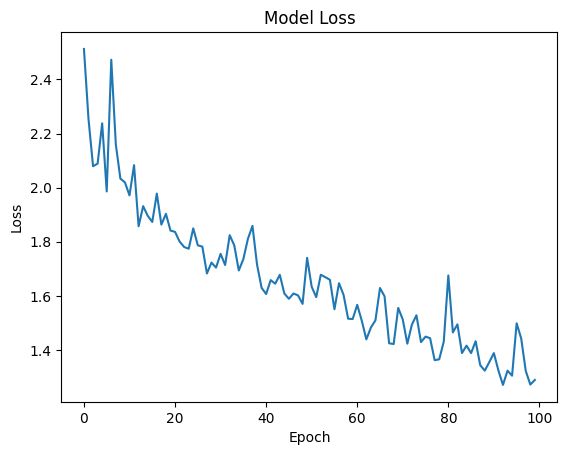

In [25]:
plt.plot(history.history['loss'])
plt.title('Model Loss')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.show()